In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [42]:
data = pd.read_csv("Salary_dataset.csv")

In [43]:
data.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [44]:
data.tail()

,Unnamed: 0,YearsExperience,Salary
25,25,9.1,105583.0
26,26,9.6,116970.0
27,27,9.7,112636.0
28,28,10.4,122392.0
29,29,10.6,121873.0


In [45]:
data.shape

(30, 3)

In [46]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [47]:
data.describe()

,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


In [48]:
data.isnull().sum()

Unnamed: 0         0
YearsExperience    0
Salary             0
dtype: int64

In [49]:
data.drop(columns=['Unnamed: 0'], inplace=True)

In [50]:
data.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


In [51]:
 print(data.to_string())

    YearsExperience    Salary
0               1.2   39344.0
1               1.4   46206.0
2               1.6   37732.0
3               2.1   43526.0
4               2.3   39892.0
5               3.0   56643.0
6               3.1   60151.0
7               3.3   54446.0
8               3.3   64446.0
9               3.8   57190.0
10              4.0   63219.0
11              4.1   55795.0
12              4.1   56958.0
13              4.2   57082.0
14              4.6   61112.0
15              5.0   67939.0
16              5.2   66030.0
17              5.4   83089.0
18              6.0   81364.0
19              6.1   93941.0
20              6.9   91739.0
21              7.2   98274.0
22              8.0  101303.0
23              8.3  113813.0
24              8.8  109432.0
25              9.1  105583.0
26              9.6  116970.0
27              9.7  112636.0
28             10.4  122392.0
29             10.6  121873.0


In [52]:
data.columns

Index(['YearsExperience', 'Salary'], dtype='object')

<Axes: xlabel='YearsExperience', ylabel='Salary'>

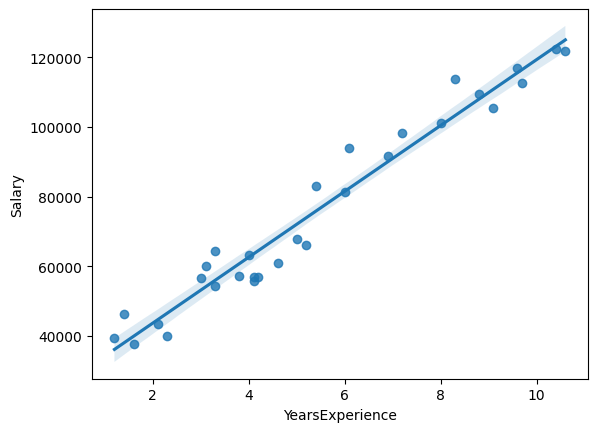

In [53]:
sns.regplot(x='YearsExperience', y='Salary', data=data)

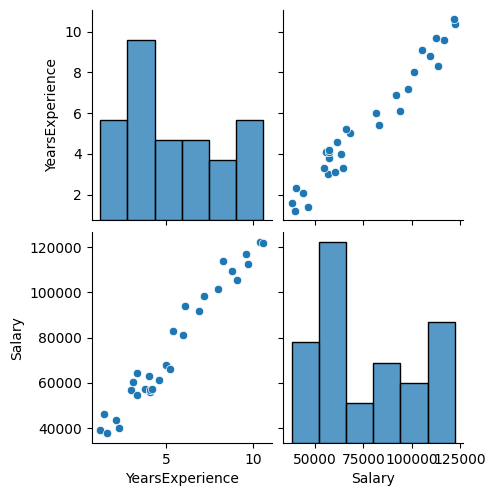

In [54]:
sns.pairplot(data)

<Axes: xlabel='YearsExperience', ylabel='Salary'>

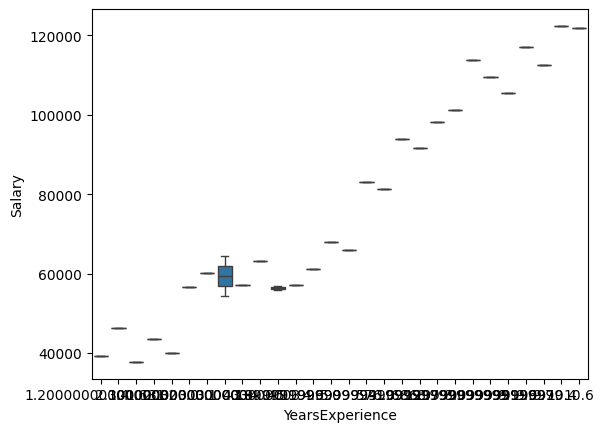

In [55]:
sns.boxplot(x='YearsExperience', y='Salary', data=data)

In [56]:
Q1 = data['Salary'].quantile(0.25)
Q3 = data['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = data[
    (data['Salary'] < lower_limit) |
    (data['Salary'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Outliers:")
print(outliers)

Q1: 56721.75
Q3: 100545.75
IQR: 43824.0
Lower limit: -9014.25
Upper limit: 166281.75
Outliers:
Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []


<Axes: >

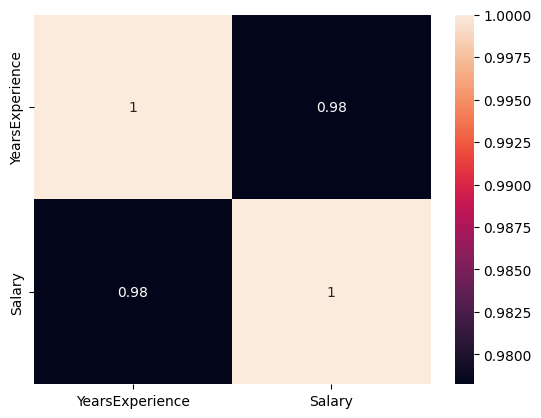

In [57]:
 sns.heatmap(data.corr(), annot=True)

In [58]:
x=data[['YearsExperience']]
y=data.Salary

In [59]:
from sklearn.model_selection import train_test_split     
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=4)

In [60]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(x_train, y_train)
y_predict = LR.predict(x_test)

In [61]:
y_test

11     55795.0
21     98274.0
28    122392.0
15     67939.0
20     91739.0
25    105583.0
Name: Salary, dtype: float64

In [62]:
y_predict

array([ 64028.97387518,  93384.75526891, 123687.49735277,  72551.62008627,
        90543.87319855, 111377.0083812 ])

In [63]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
r2score=r2_score(y_test,y_predict)

In [64]:
r2_score

<function sklearn.metrics._regression.r2_score(y_true, y_pred, *, sample_weight=None, multioutput='uniform_average', force_finite=True)>

In [65]:
print("R2 Score:", r2score)

R2 Score: 0.9504404484884268


In [66]:
x_test.shape

(6, 1)

In [67]:
adjusted_r2 = 1-(1-0.95)*(6-1)/(6-1-1)
adjusted_r2

0.9375

In [69]:
import math
print(mean_squared_error(y_test,y_predict))
print(math.sqrt(mean_squared_error(y_test,y_predict)))

24942746.41030611
4994.271359298182


In [70]:
print(mean_absolute_error(y_test,y_predict))

4336.74520465804


In [71]:
import pandas as pd

experience = pd.DataFrame({'YearsExperience': [7]})

predicted_salary = LR.predict(experience)

print("Predicted salary for 7 years of experience:", predicted_salary[0])

Predicted salary for 7 years of experience: 91490.8338886731


In [72]:
experience = pd.DataFrame({'YearsExperience': [20]})

predicted_salary = LR.predict(experience)

print("Predicted salary for 20 years of experience:", predicted_salary[0])

Predicted salary for 20 years of experience: 214595.7236043255
